# 10 — Two-key attention: fixed weights, different outputs

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/brains-to-models/blob/main/code/notebooks/10_two_key_attention.ipynb)

**Related resources:** [Paper](https://github.com/arvidl/brains-to-models/blob/main/paper/main.pdf) · [Presentation guide](https://github.com/arvidl/brains-to-models/blob/main/talk/resources.md)

## Why this notebook

An attention-weight diagram leaves out the values being combined. This two-key example exposes every multiplication so that you can see exactly what is missing. Positive weights are kept fixed while one value changes sign. The scalar output changes even though the attention pattern does not.

Use the example to distinguish a matching weight from a signed contribution to the output. The calculation is small enough to complete by hand, then extend by changing one value or the query while holding the other components fixed.

### Learning goals

1. Calculate scaled scores, normalized weights and a weighted output by hand.
2. Predict the effect of changing a value while fixing keys and query.
3. Contrast that intervention with changing the query.
4. Explain the limited sense in which a weight is a sensitivity in this example.


## Concepts and two reading paths

<details open>
<summary><strong>For biomedical and imaging readers</strong></summary>

The **query** describes what is being matched. A **key** supplies matching information for one candidate. A **value** supplies the content combined after matching. These are roles in a numerical operation, not three independently measured psychological processes.

**Softmax** turns scores into positive weights summing to one. A larger weight gives a value more influence per unit change, if the weights themselves are held fixed. It does not make the value positive. A weighted contribution depends on both its coefficient and its signed value.

For a numerical check, give both values the same number. Because the weights sum to one, the output must equal that number. Predict what happens if that common value is negative.

</details>

<details>
<summary><strong>For computational readers</strong></summary>

The keys form the rows of $K$, and the score vector is $Kq/\sqrt{d_k}$. Softmax is applied across the two candidates. After fixing $q$ and $K$, the output is the linear map $f=a^Tv$, so $\partial f/\partial v_i=a_i$.

That derivative is with respect to an independently changed internal value. A derivative with respect to an input token would also include any path through keys, query and other components. Thus the equality is exact for this intervention, rather than a general interpretation rule for a complete Transformer.

</details>


### Run in Colab or locally

**Colab:** click **Open in Colab**, connect to a standard **CPU** runtime, and run the setup cell followed by the remaining cells (**Runtime → Run all**). Setup obtains the shared code and numerical dependencies.

**Locally:** follow the [environment instructions](https://github.com/arvidl/brains-to-models/blob/main/README.md#run-the-notebooks) and select the project's Python kernel in Cursor or JupyterLab. Setup locates the checkout and sets the working directory to `code/notebooks`, so `%load ../solutions/<filename>.py` works in either environment.

Use **File → Save a copy in Drive** to retain Colab notebook edits, and download generated files before the runtime ends. See the [execution guide](https://github.com/arvidl/brains-to-models/blob/main/code/notebooks/README.md#running-and-saving) for saving outputs and starting a fresh runtime.


In [1]:
# Locate the shared code locally, or download a small checkout in Colab.
import os
from pathlib import Path
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = os.environ.get("BRAINSMODELS_REPO_URL",
                          "https://github.com/arvidl/brains-to-models.git")
if IN_COLAB:
    root = Path(os.environ.get("BRAINSMODELS_COLAB_ROOT",
                               "/content/brains-to-models"))
    if not (root / "code/src/brainsmodels").is_dir():
        # Sparse checkout keeps the large presentation out of the runtime.
        subprocess.check_call(["git", "clone", "--depth", "1", "--filter=blob:none",
                               "--sparse", "--branch", "main", REPO_URL, str(root)])
        subprocess.check_call(["git", "-C", str(root), "sparse-checkout", "set",
                               "code", "paper/figures"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "numpy>=1.26", "matplotlib>=3.8"])
else:
    here = Path.cwd().resolve()
    root = next((p for p in (here, *here.parents)
                 if (p / "pyproject.toml").is_file()
                 and (p / "code/src/brainsmodels").is_dir()), None)
    if root is None:
        raise RuntimeError("Open this notebook inside a brains-to-models checkout, "
                           "or use its Open in Colab badge.")

src = str(root / "code/src")
if src not in sys.path:
    sys.path.insert(0, src)
# Keep relative exercise paths consistent in Colab, JupyterLab and Cursor.
os.chdir(root / "code/notebooks")
repo = ROOT = root
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
print("Checkout:", root)
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__)
# End of shared setup.

from brainsmodels.paper_examples import two_key_attention

get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.dpi": 115, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
OUTPUT = ROOT / ".build/paper-examples/10_two_key_attention"

OUTPUT.mkdir(parents=True, exist_ok=True)

def show_figure(fig, name):
    fig.savefig(OUTPUT / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


Checkout: CHECKOUT
Python: 3.12.2 | NumPy: 2.5.2


## 1. Reproduce the example by hand and in code

The query is $q=(1,0)$, the rows of $K=I_2$ are the keys, and the key dimension is $d_k=2$.
There are two **scalar** values, initially $v=(2,10)$:

$$z=Kq/\sqrt{2}=(1/\sqrt{2},0),\qquad
  a_i=\frac{e^{z_i}}{e^{z_1}+e^{z_2}},\qquad f=a_1v_1+a_2v_2.$$

The first weight has the independent scalar expression
$a_1=1/(1+e^{-1/\sqrt{2}})$; $a_2=1-a_1$. The intervention changes $v_2$ from $10$ to $-10$
while holding the query and keys fixed. In this example values do not enter the weight calculation.


In [2]:
original = two_key_attention()
changed = two_key_attention(values=(2, -10))
a1 = 1 / (1 + np.exp(-1 / np.sqrt(2)))
np.testing.assert_allclose(original.weights, [a1, 1 - a1], rtol=0, atol=1e-14)
np.testing.assert_array_equal(original.weights, changed.weights)
np.testing.assert_array_equal(original.query, changed.query)
np.testing.assert_array_equal(original.keys, changed.keys)

print("Key   score       weight      v (before/after)   contribution (before/after)")
for i in range(2):
    print(f"{i+1:>3}   {original.scores[i]: .6f}   {original.weights[i]:.6f}"
          f"       {original.values[i]:>3.0f} / {changed.values[i]:>3.0f}"
          f"             {original.contributions[i]: .6f} / {changed.contributions[i]: .6f}")
print(f"Outputs: {original.output:.10f} and {changed.output:.10f}")
print(f"Paper rounding: {original.output:.4f} and {changed.output:.4f}")

reference = json.loads((ROOT / "paper/figures/appendix_values.json").read_text())["attention"]
np.testing.assert_allclose(original.weights, reference["weights"], rtol=0, atol=1e-14)
assert original.output == reference["output"]
assert changed.output == reference["changed_value_output"]
assert (f"{original.output:.4f}", f"{changed.output:.4f}") == ("4.6419", "-1.9629")


Key   score       weight      v (before/after)   contribution (before/after)
  1    0.707107   0.669762         2 /   2              1.339523 /  1.339523
  2    0.000000   0.330238        10 / -10              3.302385 / -3.302385
Outputs: 4.6419076054 and -1.9628614081
Paper rounding: 4.6419 and -1.9629


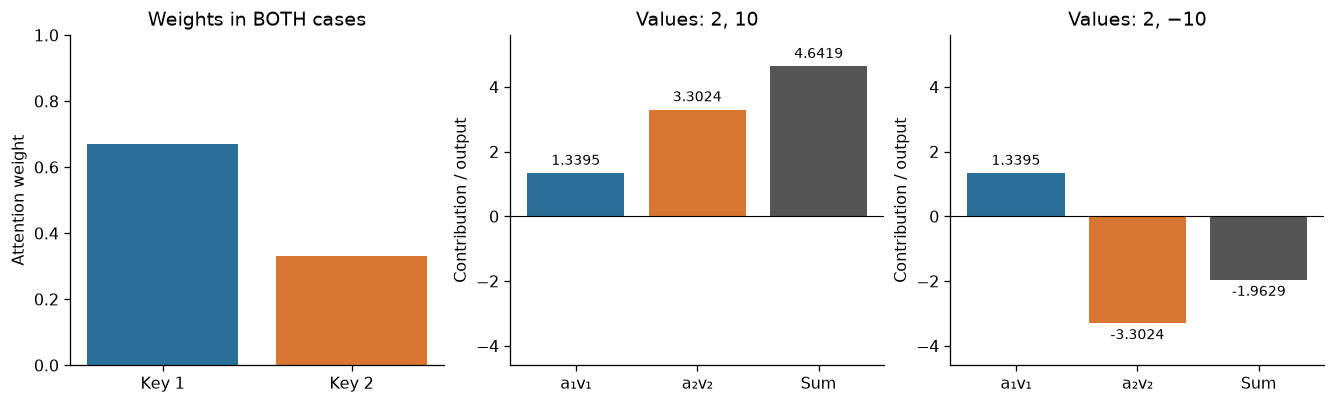

In [3]:
colors = ["#2a6f97", "#d97732", "#555555"]
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.4), layout="constrained")
axes[0].bar(["Key 1", "Key 2"], original.weights, color=colors[:2])
axes[0].set(title="Weights in BOTH cases", ylabel="Attention weight", ylim=(0, 1))
for ax, result, title in zip(axes[1:], [original, changed], ["Values: 2, 10", "Values: 2, −10"]):
    amounts = [*result.contributions, result.output]
    ax.bar(["a₁v₁", "a₂v₂", "Sum"], amounts, color=colors)
    ax.axhline(0, color="black", lw=0.7)
    ax.set(title=title, ylabel="Contribution / output", ylim=(-4.6, 5.6))
    for i, value in enumerate(amounts):
        ax.text(i, value + (0.15 if value >= 0 else -0.15), f"{value:.4f}",
                ha="center", va="bottom" if value >= 0 else "top", fontsize=9)
show_figure(fig, "weights_and_contributions")


**Result.** The same weights, approximately $(0.6698,0.3302)$, produce $4.6419$ and $-1.9629$.
The weight on the second key stays positive while its contribution changes sign.
A plot of weights alone therefore omits a quantity needed to compute this output.

## 2. A controlled value intervention

Keep $q$, $K$ and $v_1=2$ fixed and sweep $v_2$. The output is a straight line,
$f(v_2)=2a_1+a_2v_2$, with slope $a_2$ and zero crossing $-2a_1/a_2$.
Thus $f(10)-f(-10)=20a_2$. Predict the sign of the output at $v_2=-5$ before running.


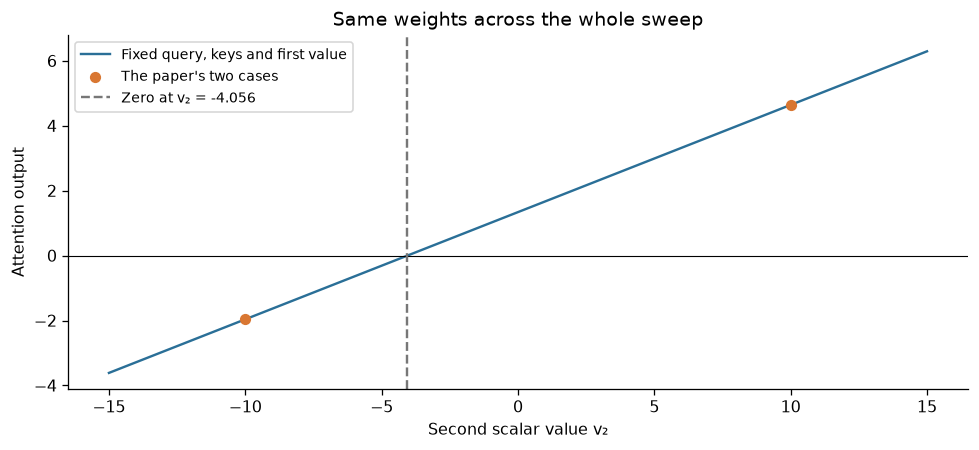

At v₂ = −5: -0.3117


In [4]:
second_values = np.linspace(-15, 15, 121)
sweep = [two_key_attention(values=(2, value)) for value in second_values]
outputs = np.array([example.output for example in sweep])
np.testing.assert_allclose([example.weights for example in sweep],
                           np.tile(original.weights, (len(sweep), 1)), rtol=0, atol=0)
np.testing.assert_allclose(outputs, 2 * original.weights[0] + second_values * original.weights[1])
assert np.isclose(original.output - changed.output, 20 * original.weights[1])
zero = -2 * original.weights[0] / original.weights[1]

fig, ax = plt.subplots(figsize=(8.4, 3.8), layout="constrained")
ax.plot(second_values, outputs, color=colors[0], label="Fixed query, keys and first value")
ax.scatter([10, -10], [original.output, changed.output], color=colors[1], zorder=3,
           label="The paper's two cases")
ax.axhline(0, color="black", lw=0.7)
ax.axvline(zero, color="#777777", ls="--", label=f"Zero at v₂ = {zero:.3f}")
ax.set(xlabel="Second scalar value v₂", ylabel="Attention output", title="Same weights across the whole sweep")
ax.legend(fontsize=9)
show_figure(fig, "value_intervention")
print(f"At v₂ = −5: {two_key_attention(values=(2, -5)).output:.4f}")


## 3. Change the query instead

This time hold both values at $(2,10)$ and exchange the query coordinates.
The scores and weights now exchange positions. This is a different intervention from changing a value.


In [5]:
new_query = two_key_attention(query=(0, 1))
np.testing.assert_allclose(new_query.weights, original.weights[::-1])
print("Original query:", original.query, "weights:", original.weights.round(6),
      "output:", round(original.output, 6))
print("Changed query: ", new_query.query, "weights:", new_query.weights.round(6),
      "output:", round(new_query.output, 6))
(OUTPUT / "results.json").write_text(json.dumps({
    "weights": original.weights.tolist(), "output": original.output,
    "changed_value_output": changed.output, "changed_query_output": new_query.output,
    "value_zero_crossing": zero,
}, indent=2))


Original query: [1. 0.] weights: [0.669762 0.330238] output: 4.641908
Changed query:  [0. 1.] weights: [0.330238 0.669762] output: 7.358092


237

## Explain the intervention in words and symbols

The second key receives a smaller positive weight than the first, yet its value can dominate the output if its magnitude is sufficiently large. With $v_2=10$, its contribution is positive. With $v_2=-10$, its contribution is negative. The matching calculation is unchanged. This is an explicit pair of outputs sharing one attention map.

In the sweep plot, the slope is $a_2$, and the intercept is $2a_1$. Solve for the zero crossing before reading it from the graph. Then set both values equal: because the weights sum to one, the output must equal that common value regardless of how the two weights are distributed. This gives a second useful counterexample to explaining an output from a weight pattern alone.

Exchanging query coordinates changes the matching scores, so it answers a different question. Explain which variables were fixed in each comparison. If you later change an actual input token in a trained network, remember that its key and value can change together. The clean independent intervention here is a tool for understanding the computation, not a guarantee that the same variable can be isolated in a real input.


## Reflection and extensions

- Which statement does the weight $a_2$ support: how the output responds to a scalar value here,
  or why a complete model made a decision? What else would the second statement require?
- Try values $(0,0)$ and then $(100,100)$. Explain why the weights stay fixed although the outputs differ.
- In a trained transformer, keys and values can both depend on the same input. Changing an input token
  is therefore a different experiment from independently changing this internal scalar value.

In this calculation, reconstructing the output requires both the weights and signed values. A larger model adds output projections, multiple heads, residual paths and nonlinear layers, which supply further dependencies to examine. Continue with [notebook 08](https://github.com/arvidl/brains-to-models/blob/main/code/notebooks/08_attention_maps.ipynb) to compare attention, gradients and occlusion on one common synthetic model.

**Method reference:** Vaswani et al. (2017), *Attention Is All You Need*,
[scaled dot-product attention, §3.2.1](https://arxiv.org/abs/1706.03762).
The parameters above fully specify the two-key calculation.
